# Section 1: Import libraries and configure paths

In [15]:
# ============================================================
# Import Libraries and Configure Project Paths
# ============================================================

import os
import hashlib
import pandas as pd

from PIL import Image
from pathlib import Path
from collections import defaultdict

# Project directory
PROJECT_DIR = Path("C:/Users/aurna/Documents/brac_thesis")

# Dataset directory
DATASET_DIR = PROJECT_DIR / "dataset"

# Metadata directory
METADATA_DIR = PROJECT_DIR / "metadata"

# Dataset splits
SPLITS = ["train", "test", "validation"]

# Disease categories and their respective severity levels
CLASS_STRUCTURE = {
    "acne": ["mild", "moderate", "severe"],
    "eczema": ["mild", "moderate", "severe"],
    "normal": ["dry", "oily", "normal"],
    "burn": ["mild", "moderate", "severe"]
}

# Supported image extensions
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp",
    ".tif",
    ".tiff"
}

# Create metadata directory if it does not exist
METADATA_DIR.mkdir(parents=True, exist_ok=True)

# Check project directory
assert PROJECT_DIR.exists(), "Project directory does not exist!"

assert DATASET_DIR.exists(), "Dataset directory does not exist!"

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Metadata directory:", METADATA_DIR)

print("\nConfiguration completed successfully!")

Project directory: C:\Users\aurna\Documents\brac_thesis
Dataset directory: C:\Users\aurna\Documents\brac_thesis\dataset
Metadata directory: C:\Users\aurna\Documents\brac_thesis\metadata

Configuration completed successfully!


# Section 2: Check image accessibility

In [16]:
# ============================================================
# Check Image Accessibility
# ============================================================

accessibility_results = []

for split in SPLITS:

    for disease, severities in CLASS_STRUCTURE.items():

        for severity in severities:

            folder = DATASET_DIR / split / disease / severity

            if not folder.exists():

                print("Missing folder:", folder)
                continue

            for image_path in sorted(folder.iterdir()):

                if not image_path.is_file():
                    continue

                if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                try:

                    # Check file accessibility
                    accessible = os.access(image_path, os.R_OK)

                    # Try opening and reading the image
                    with open(image_path, "rb") as file:
                        file.read(1)

                    with Image.open(image_path) as img:
                        img.load()

                    status = "Accessible" if accessible else "Not Accessible"

                except Exception as e:

                    status = "Not Accessible"

                accessibility_results.append({

                    "split": split,
                    "disease": disease,
                    "severity": severity,
                    "filename": image_path.name,
                    "filepath": str(image_path),
                    "status": status

                })


accessibility_df = pd.DataFrame(accessibility_results)

print("Accessibility Check Completed!")

print("\nAccessibility Summary:")

print(
    accessibility_df["status"].value_counts()
)

# Display inaccessible images
inaccessible_df = accessibility_df[
    accessibility_df["status"] != "Accessible"
]

print("\nInaccessible Images:")

display(inaccessible_df)

Accessibility Check Completed!

Accessibility Summary:
status
Accessible    9271
Name: count, dtype: int64

Inaccessible Images:


,split,disease,severity,filename,filepath,status


# Section 3: Check image modes

In [17]:
# ============================================================
# Check Image Modes
# ============================================================

mode_results = []

for split in SPLITS:

    for disease, severities in CLASS_STRUCTURE.items():

        for severity in severities:

            folder = DATASET_DIR / split / disease / severity

            if not folder.exists():
                continue

            for image_path in sorted(folder.iterdir()):

                if not image_path.is_file():
                    continue

                if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                try:

                    with Image.open(image_path) as img:

                        mode = img.mode

                        width, height = img.size

                    mode_results.append({

                        "split": split,
                        "disease": disease,
                        "severity": severity,
                        "filename": image_path.name,
                        "mode": mode,
                        "width": width,
                        "height": height

                    })

                except Exception:
                    continue


mode_df = pd.DataFrame(mode_results)

print("Image Mode Inspection Completed!")

print("\nImage Mode Distribution:")

display(
    mode_df["mode"].value_counts().to_frame("Image Count")
)

print("\nImages Not in RGB Mode:")

non_rgb_df = mode_df[
    mode_df["mode"] != "RGB"
]

display(non_rgb_df)

Image Mode Inspection Completed!

Image Mode Distribution:


,Image Count
mode,
RGB,9271



Images Not in RGB Mode:


,split,disease,severity,filename,mode,width,height


# Section 4: Identify invalid and corrupted images

In [18]:
# ============================================================
# Check Invalid Images
# ============================================================

invalid_images = []
valid_images = []

for split in SPLITS:

    for disease, severities in CLASS_STRUCTURE.items():

        for severity in severities:

            folder = DATASET_DIR / split / disease / severity

            if not folder.exists():
                continue

            for image_path in sorted(folder.iterdir()):

                if not image_path.is_file():
                    continue

                if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                try:

                    # First verification
                    with Image.open(image_path) as img:
                        img.verify()

                    # Reopen and load completely
                    with Image.open(image_path) as img:
                        img.load()

                    valid_images.append(image_path)

                except Exception as e:

                    invalid_images.append({

                        "split": split,
                        "disease": disease,
                        "severity": severity,
                        "filename": image_path.name,
                        "filepath": str(image_path),
                        "error": str(e)

                    })


invalid_df = pd.DataFrame(invalid_images)

print("Invalid Image Check Completed!")

print("\nTotal Valid Images:", len(valid_images))

print("Total Invalid Images:", len(invalid_images))

if not invalid_df.empty:

    display(invalid_df)

else:

    print("\nNo invalid images found!")

Invalid Image Check Completed!

Total Valid Images: 9271
Total Invalid Images: 0

No invalid images found!


# Section 5: Resize images and convert to RGB

## 5.1 Configure image dimensions

In [19]:
# ============================================================
# Configure Image Dimensions
# ============================================================

IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

TARGET_SIZE = (IMAGE_WIDTH, IMAGE_HEIGHT)

print("Target Image Size:", TARGET_SIZE)
print("Target Image Mode: RGB")

Target Image Size: (224, 224)
Target Image Mode: RGB


## 5.2 Resize and convert images

In [20]:
# ============================================================
# Resize Images and Convert to RGB
# ============================================================

from PIL import Image, ImageOps

processed_images = []
processing_errors = []

for image_path in valid_images:

    try:

        with Image.open(image_path) as img:

            # Correct image orientation using EXIF metadata
            img = ImageOps.exif_transpose(img)

            # Convert image to RGB
            img = img.convert("RGB")

            # Resize image to 224 x 224
            img = img.resize(
                TARGET_SIZE,
                Image.Resampling.LANCZOS
            )

            # Save image in the same location
            img.save(image_path)

        processed_images.append(image_path)

    except Exception as e:

        processing_errors.append({

            "filepath": str(image_path),
            "error": str(e)

        })


print("Image Processing Completed!")

print("Successfully Processed:", len(processed_images))

print("Processing Errors:", len(processing_errors))

if processing_errors:

    display(pd.DataFrame(processing_errors))

Image Processing Completed!
Successfully Processed: 9271
Processing Errors: 0


## 5.3 Verify resized images 

In [21]:
# ============================================================
# Verify Image Dimensions and RGB Mode
# ============================================================

verification_results = []

for image_path in processed_images:

    try:

        with Image.open(image_path) as img:

            width, height = img.size

            mode = img.mode

        verification_results.append({

            "filename": image_path.name,
            "width": width,
            "height": height,
            "mode": mode,
            "valid": (
                width == IMAGE_WIDTH
                and height == IMAGE_HEIGHT
                and mode == "RGB"
            )

        })

    except Exception as e:

        print("Verification Error:", image_path, e)


verification_df = pd.DataFrame(verification_results)

print("Image Verification Summary:")

display(
    verification_df["valid"].value_counts()
    .to_frame("Image Count")
)

print("\nImages That Failed Verification:")

display(
    verification_df[
        verification_df["valid"] == False
    ]
)

Image Verification Summary:


,Image Count
valid,
True,9271



Images That Failed Verification:


,filename,width,height,mode,valid


# Section 6: Rename all valid images

In [22]:
# ============================================================
# Rename Images
# ============================================================

import uuid

renamed_images = []

rename_errors = []


for split in SPLITS:

    for disease, severities in CLASS_STRUCTURE.items():

        for severity in severities:

            folder = DATASET_DIR / split / disease / severity

            if not folder.exists():
                continue

            # Select valid images from this folder
            images = [

                path for path in valid_images

                if path.parent == folder

            ]

            images = sorted(images, key=lambda p: p.name.lower())

            # First stage: rename to temporary filenames
            temporary_files = []

            for image_path in images:

                try:

                    temp_path = image_path.with_name(
                        f"__temp_{uuid.uuid4().hex}{image_path.suffix.lower()}"
                    )

                    image_path.rename(temp_path)

                    temporary_files.append(temp_path)

                except Exception as e:

                    rename_errors.append({

                        "filepath": str(image_path),
                        "error": str(e)

                    })

            # Second stage: assign final filenames
            for serial_number, temp_path in enumerate(
                temporary_files,
                start=1
            ):

                try:

                    extension = temp_path.suffix.lower()

                    new_filename = (
                        f"{disease}_{severity}_{serial_number:03d}{extension}"
                    )

                    new_path = folder / new_filename

                    temp_path.rename(new_path)

                    renamed_images.append({

                        "split": split,
                        "disease": disease,
                        "severity": severity,
                        "filename": new_filename,
                        "filepath": new_path

                    })

                except Exception as e:

                    rename_errors.append({

                        "filepath": str(temp_path),
                        "error": str(e)

                    })


print("Image Renaming Completed!")

print("Successfully Renamed:", len(renamed_images))

print("Renaming Errors:", len(rename_errors))

if rename_errors:

    display(pd.DataFrame(rename_errors))

else:

    print("No renaming errors found!")

Image Renaming Completed!
Successfully Renamed: 9271
Renaming Errors: 0
No renaming errors found!


# Section 7: Generate CSV Metadata Files

In [23]:

# ============================================================
# Generate CSV Metadata Files
# ============================================================

# Create metadata directory
METADATA_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# Generate Three CSV Files
# ------------------------------------------------------------

for split in SPLITS:

    metadata_records = []

    # Iterate through all diseases
    for disease, severities in CLASS_STRUCTURE.items():

        # Iterate through severity levels
        for severity in severities:

            image_folder = (
                DATASET_DIR /
                split /
                disease /
                severity
            )

            if not image_folder.exists():
                continue

            # Collect image information
            for image_path in sorted(image_folder.iterdir()):

                if not image_path.is_file():
                    continue

                if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                    continue

                # Combined class label
                label = (
                    f"{disease.capitalize()}_"
                    f"{severity.capitalize()}"
                )

                metadata_records.append({

                    "filepath": image_path.as_posix(),

                    "filename": image_path.name,

                    "disease": disease,

                    "severity": severity,

                    "label": label

                })


    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    metadata_df = pd.DataFrame(

        metadata_records,

        columns=[
            "filepath",
            "filename",
            "disease",
            "severity",
            "label"
        ]

    )


    # --------------------------------------------------------
    # Save CSV File
    # --------------------------------------------------------

    csv_path = METADATA_DIR / f"{split}.csv"

    metadata_df.to_csv(

        csv_path,

        index=False,

        encoding="utf-8"

    )


    print(
        f"{split.capitalize()} | "
        f"Total Images: {len(metadata_df)} | "
        f"Saved: {csv_path}"
    )


print("\nMetadata CSV Files Generated Successfully!")

Train | Total Images: 7021 | Saved: C:\Users\aurna\Documents\brac_thesis\metadata\train.csv
Test | Total Images: 1063 | Saved: C:\Users\aurna\Documents\brac_thesis\metadata\test.csv
Validation | Total Images: 1187 | Saved: C:\Users\aurna\Documents\brac_thesis\metadata\validation.csv

Metadata CSV Files Generated Successfully!


# Section 8: Verify generated CSV files

In [24]:

# ============================================================
# Verify Generated Metadata
# ============================================================

required_columns = [
    "filepath",
    "filename",
    "disease",
    "severity",
    "label"
]

verification_results = []

# ------------------------------------------------------------
# Verify Each CSV File
# ------------------------------------------------------------

for split in SPLITS:

    csv_path = METADATA_DIR / f"{split}.csv"

    if not csv_path.exists():

        print("Missing CSV:", csv_path)
        continue

    # Load CSV
    df = pd.read_csv(csv_path)

    # Check columns
    columns_valid = list(df.columns) == required_columns

    # Check image paths
    paths_exist = df["filepath"].apply(
        lambda path: Path(path).is_file()
    )

    # Check missing values
    missing_values = df.isnull().sum().sum()

    # Check duplicate filepaths
    duplicate_paths = df["filepath"].duplicated().sum()

    verification_results.append({

        "split": split,

        "total_images": len(df),

        "valid_columns": columns_valid,

        "existing_images": paths_exist.sum(),

        "missing_images": (~paths_exist).sum(),

        "missing_values": missing_values,

        "duplicate_paths": duplicate_paths

    })


# ------------------------------------------------------------
# Display Verification Results
# ------------------------------------------------------------

verification_df = pd.DataFrame(
    verification_results
)

display(verification_df)


# ------------------------------------------------------------
# Overall Verification Summary
# ------------------------------------------------------------

print("\nTotal CSV Files:", len(verification_df))

if not verification_df.empty:

    print(
        "Total Metadata Records:",
        verification_df["total_images"].sum()
    )

    print(
        "Total Existing Images:",
        verification_df["existing_images"].sum()
    )

    print(
        "Total Missing Images:",
        verification_df["missing_images"].sum()
    )

    print(
        "Total Missing Values:",
        verification_df["missing_values"].sum()
    )

    print(
        "Total Duplicate Paths:",
        verification_df["duplicate_paths"].sum()
    )


print("\nMetadata Verification Completed!")


,split,total_images,valid_columns,existing_images,missing_images,missing_values,duplicate_paths
0,train,7021,True,7021,0,0,0
1,test,1063,True,1063,0,0,0
2,validation,1187,True,1187,0,0,0



Total CSV Files: 3
Total Metadata Records: 9271
Total Existing Images: 9271
Total Missing Images: 0
Total Missing Values: 0
Total Duplicate Paths: 0

Metadata Verification Completed!


# Section 9: Visualize dataset distribution

## 9.1 Import visualization libraries and load metadata

In [25]:

# ============================================================
# Dataset Distribution Visualization
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Set visualization style
sns.set_theme(style="whitegrid")


# ------------------------------------------------------------
# Load All Metadata CSV Files
# ------------------------------------------------------------

all_metadata = []

for split in SPLITS:

    csv_path = METADATA_DIR / f"{split}.csv"

    df = pd.read_csv(csv_path)

    # Add dataset split information
    df["split"] = split

    all_metadata.append(df)


# ------------------------------------------------------------
# Combine All Metadata
# ------------------------------------------------------------

dataset_df = pd.concat(
    all_metadata,
    ignore_index=True
)


# ------------------------------------------------------------
# Dataset Overview
# ------------------------------------------------------------

print("=" * 60)

print("DATASET OVERVIEW")

print("=" * 60)

print("\nTotal Images:", len(dataset_df))

print("\nDataset Distribution by Split:")

print(
    dataset_df["split"].value_counts()
)

print("\nDataset Distribution by Disease:")

print(
    dataset_df["disease"].value_counts()
)

print("\nDataset Distribution by Severity:")

print(
    dataset_df["severity"].value_counts()
)

print("\nDataset Overview:")

display(dataset_df.head())

print("\nMetadata Loaded Successfully!")

DATASET OVERVIEW

Total Images: 9271

Dataset Distribution by Split:
split
train         7021
validation    1187
test          1063
Name: count, dtype: int64

Dataset Distribution by Disease:
disease
normal    3152
burn      2219
eczema    1950
acne      1950
Name: count, dtype: int64

Dataset Distribution by Severity:
severity
moderate    2292
mild        2172
severe      1655
normal      1274
oily        1120
dry          758
Name: count, dtype: int64

Dataset Overview:


,filepath,filename,disease,severity,label,split
0,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_001.jpg,acne,mild,Acne_Mild,train
1,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_002.png,acne,mild,Acne_Mild,train
2,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_003.jpg,acne,mild,Acne_Mild,train
3,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_004.jpg,acne,mild,Acne_Mild,train
4,C:/Users/aurna/Documents/brac_thesis/dataset/t...,acne_mild_005.jpg,acne,mild,Acne_Mild,train



Metadata Loaded Successfully!


## 9.2 Visualize the number of images in each disease

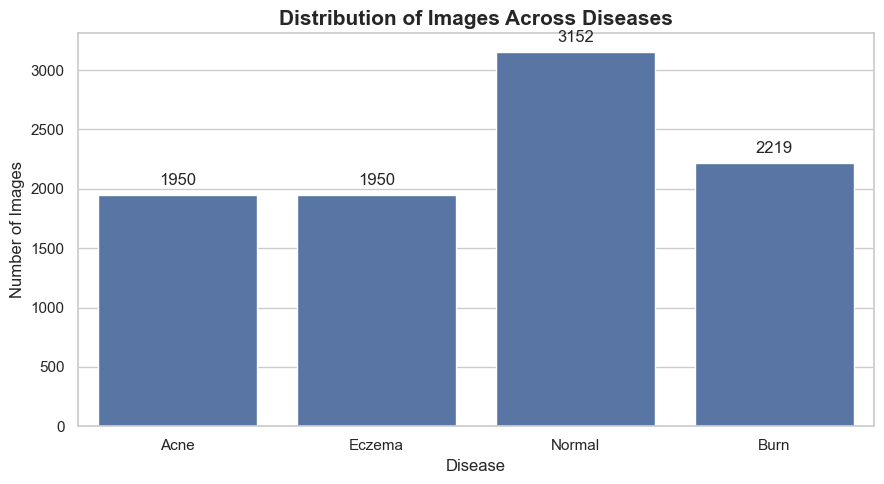

In [26]:
# ============================================================
# Image Distribution Across Diseases
# ============================================================

disease_counts = (
    dataset_df["disease"]
    .value_counts()
    .reindex(CLASS_STRUCTURE.keys())
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=disease_counts.index.str.capitalize(),
    y=disease_counts.values
)

# Add image counts above bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=5
    )

plt.title(
    "Distribution of Images Across Diseases",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disease", fontsize=12)

plt.ylabel("Number of Images", fontsize=12)

plt.tight_layout()

plt.show()

## 9.3 Visualize the number of images in each severity level

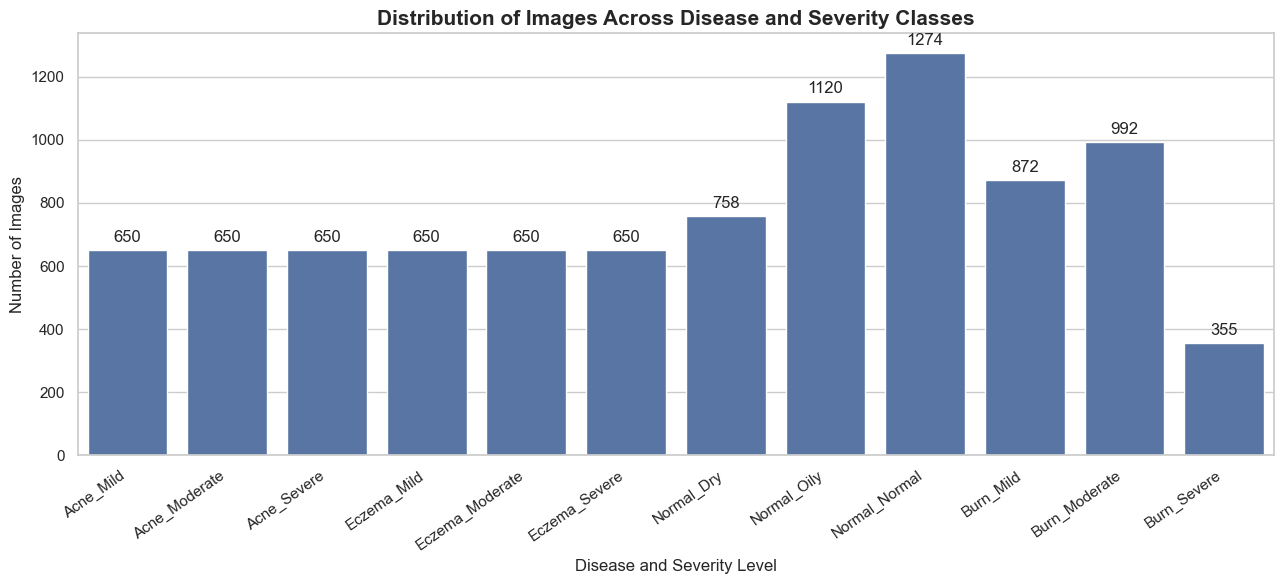

In [27]:
# ============================================================
# Image Distribution Across Severity Levels
# ============================================================

class_counts = (
    dataset_df["label"]
    .value_counts()
)

class_order = [
    "Acne_Mild",
    "Acne_Moderate",
    "Acne_Severe",
    "Eczema_Mild",
    "Eczema_Moderate",
    "Eczema_Severe",
    "Normal_Dry",
    "Normal_Oily",
    "Normal_Normal",
    "Burn_Mild",
    "Burn_Moderate",
    "Burn_Severe"
]

class_counts = class_counts.reindex(
    class_order,
    fill_value=0
)

plt.figure(figsize=(13, 6))

ax = sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=4
    )

plt.title(
    "Distribution of Images Across Disease and Severity Classes",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disease and Severity Level", fontsize=12)

plt.ylabel("Number of Images", fontsize=12)

plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.show()

## 9.4 Compare severity distribution within each disease

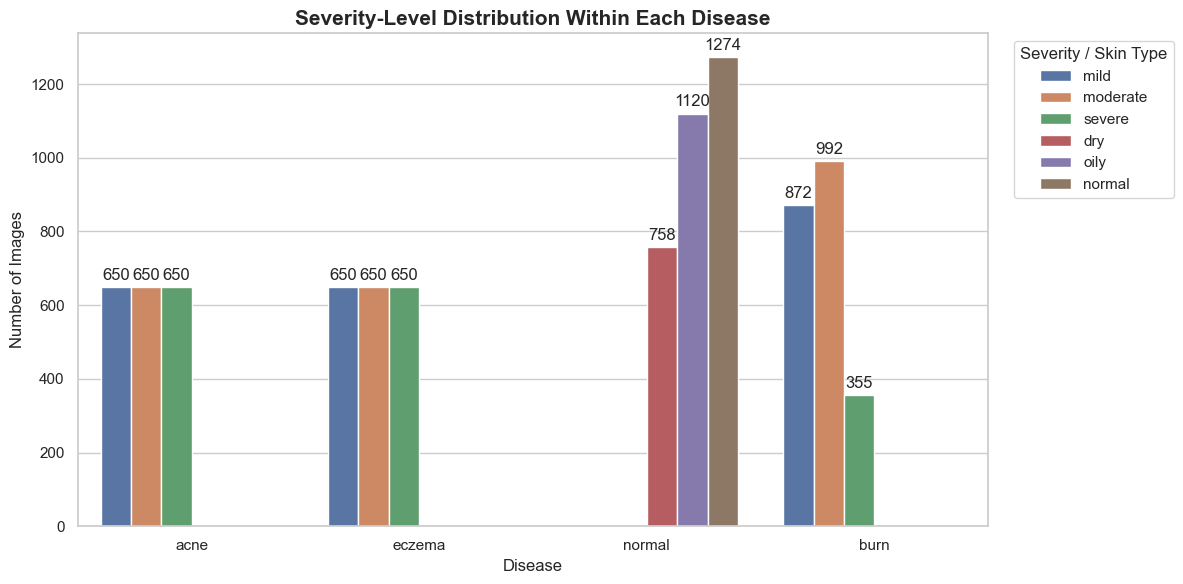

In [28]:
# ============================================================
# Severity Distribution Within Each Disease
# ============================================================

plt.figure(figsize=(12, 6))

ax = sns.countplot(
    data=dataset_df,
    x="disease",
    hue="severity",
    order=["acne", "eczema", "normal", "burn"],
    hue_order=[
        "mild",
        "moderate",
        "severe",
        "dry",
        "oily",
        "normal"
    ]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3
    )

plt.title(
    "Severity-Level Distribution Within Each Disease",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disease", fontsize=12)

plt.ylabel("Number of Images", fontsize=12)

plt.legend(
    title="Severity / Skin Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.show()

## 9.5 Compare Train, Validation, and Test distributions

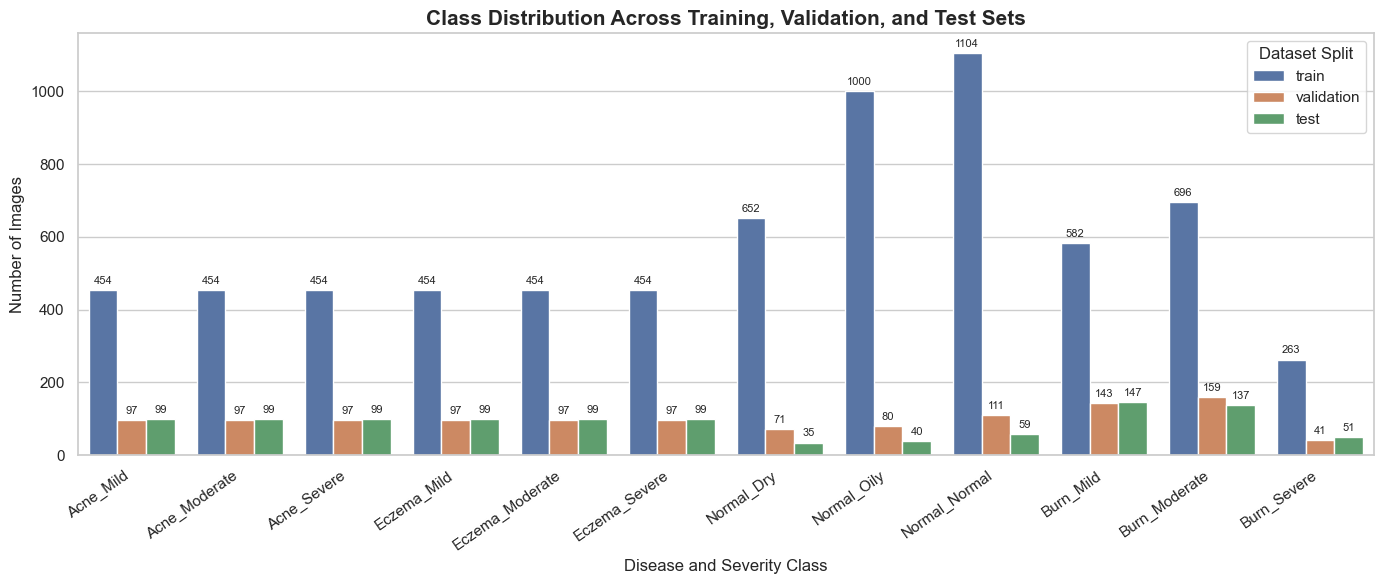

In [29]:
# ============================================================
# Dataset Split Distribution
# ============================================================

plt.figure(figsize=(14, 6))

ax = sns.countplot(
    data=dataset_df,
    x="label",
    hue="split",
    order=class_order,
    hue_order=["train", "validation", "test"]
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%d",
        padding=3,
        fontsize=8
    )

plt.title(
    "Class Distribution Across Training, Validation, and Test Sets",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Disease and Severity Class", fontsize=12)

plt.ylabel("Number of Images", fontsize=12)

plt.xticks(rotation=35, ha="right")

plt.legend(title="Dataset Split")

plt.tight_layout()

plt.savefig(f'{PROJECT_DIR}/results/class_distribution_train_test_validation.png',
            dpi=300,
            bbox_inches='tight')

plt.show()

## 9.6 Generate a numerical summary

In [30]:
# ============================================================
# Dataset Distribution Summary
# ============================================================

distribution_summary = pd.crosstab(
    dataset_df["label"],
    dataset_df["split"]
)

distribution_summary = distribution_summary.reindex(
    class_order,
    fill_value=0
)

distribution_summary["Total"] = (
    distribution_summary.sum(axis=1)
)

distribution_summary.loc["Total"] = (
    distribution_summary.sum(axis=0)
)

display(distribution_summary)

split,test,train,validation,Total
label,,,,
Acne_Mild,99,454,97,650
Acne_Moderate,99,454,97,650
Acne_Severe,99,454,97,650
Eczema_Mild,99,454,97,650
Eczema_Moderate,99,454,97,650
Eczema_Severe,99,454,97,650
Normal_Dry,35,652,71,758
Normal_Oily,40,1000,80,1120
Normal_Normal,59,1104,111,1274


## 9.7 - Sample Images Across Disease Classes and Dataset Splits


Displaying Samples for Split: TRAIN


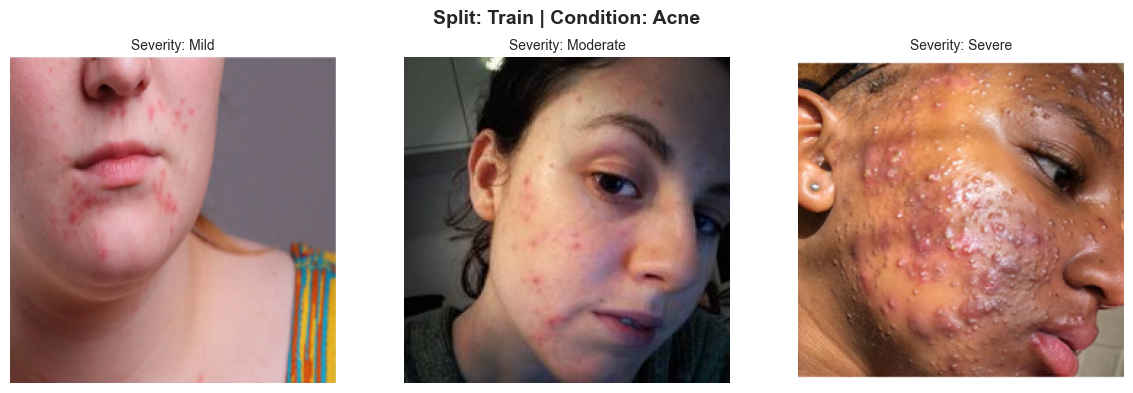

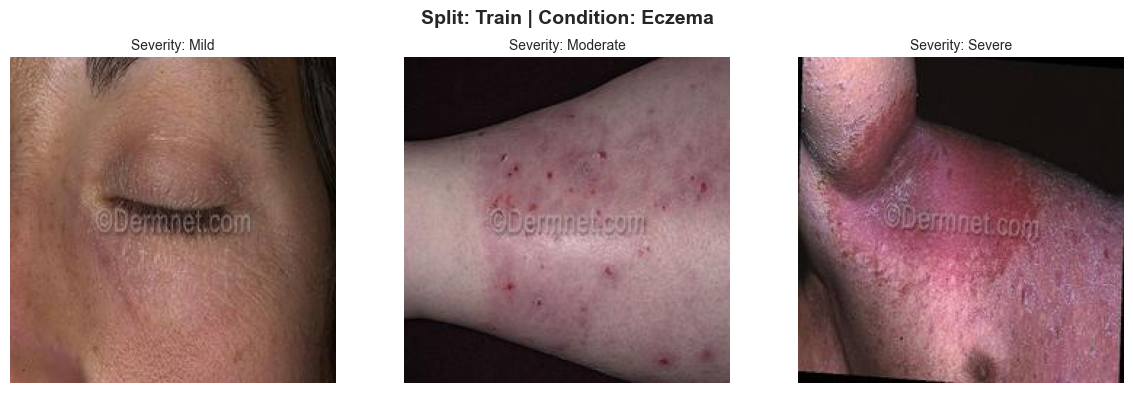

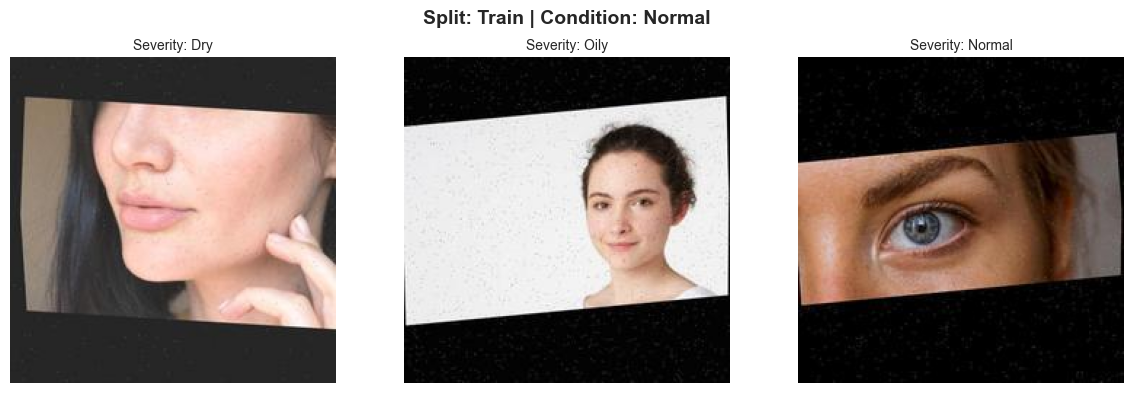

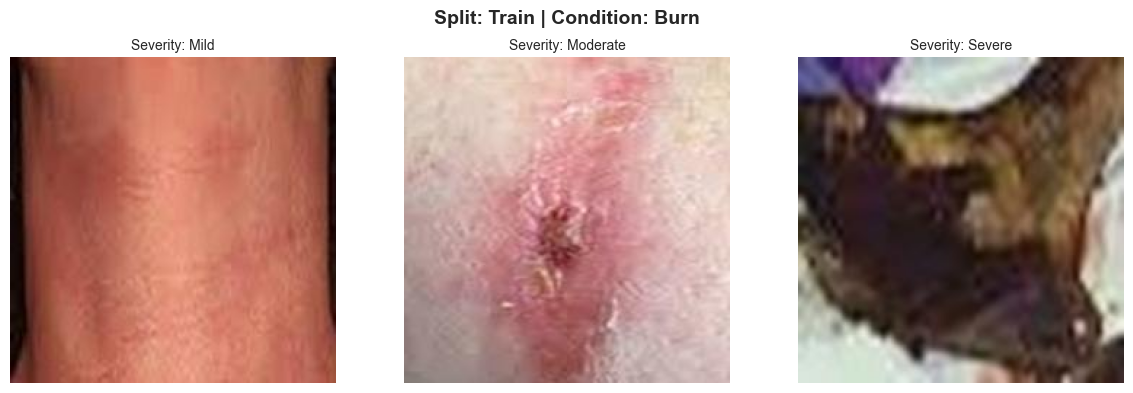


Displaying Samples for Split: TEST


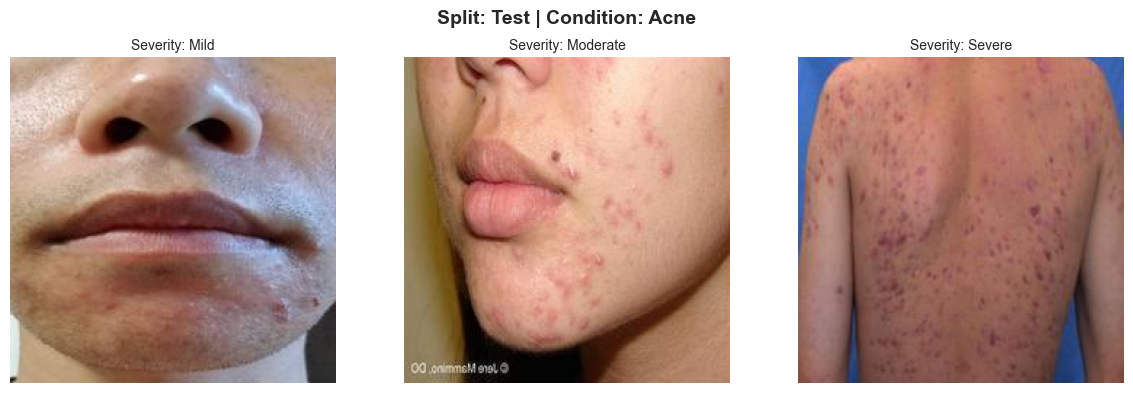

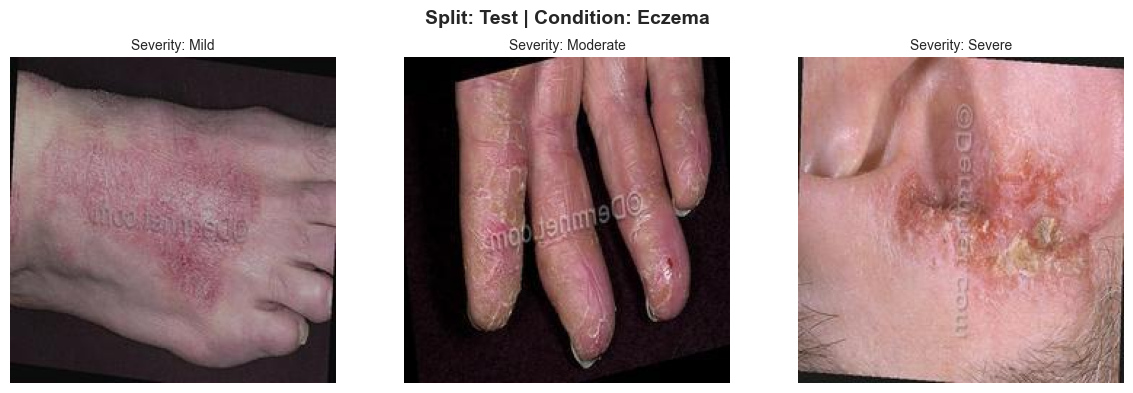

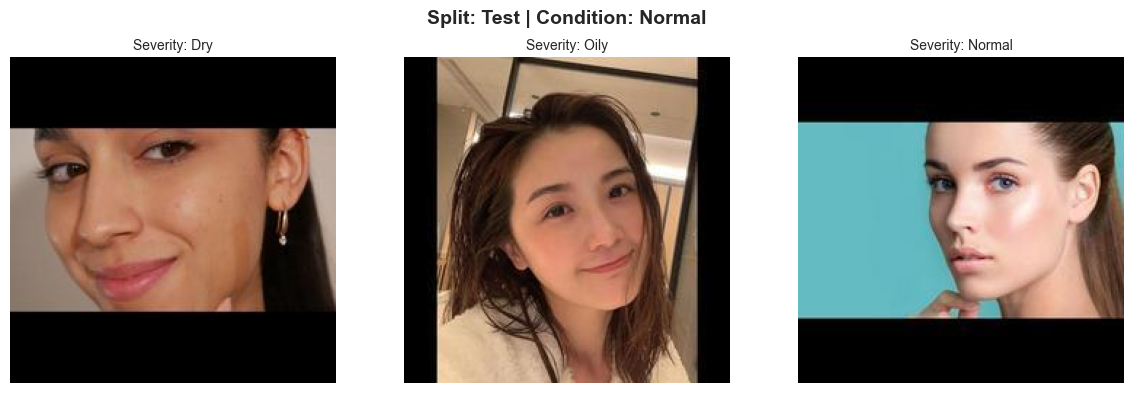

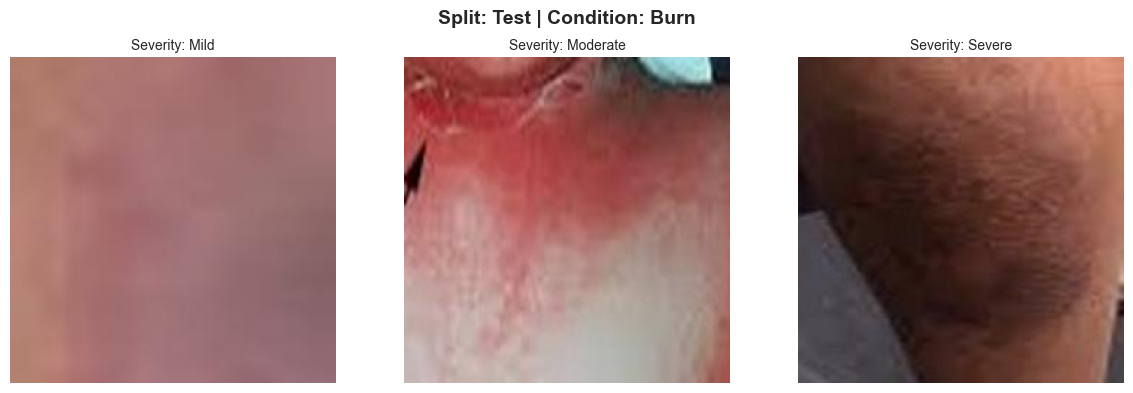


Displaying Samples for Split: VALIDATION


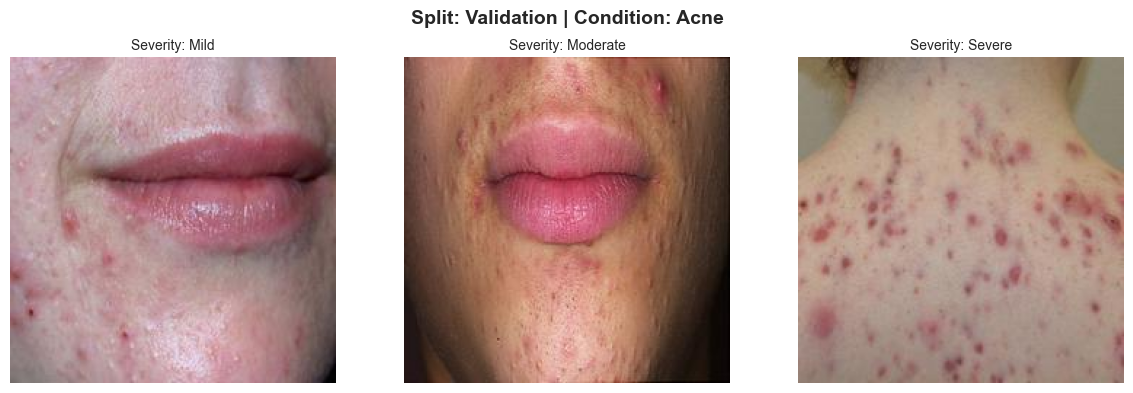

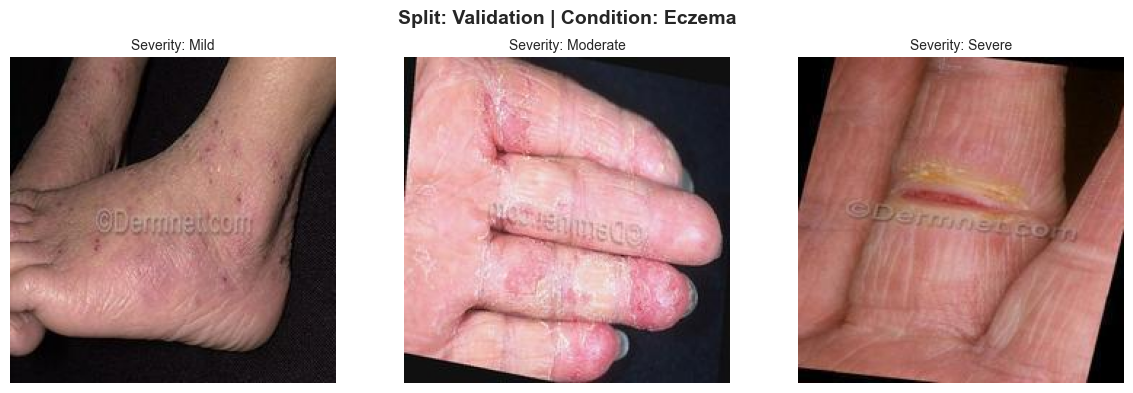

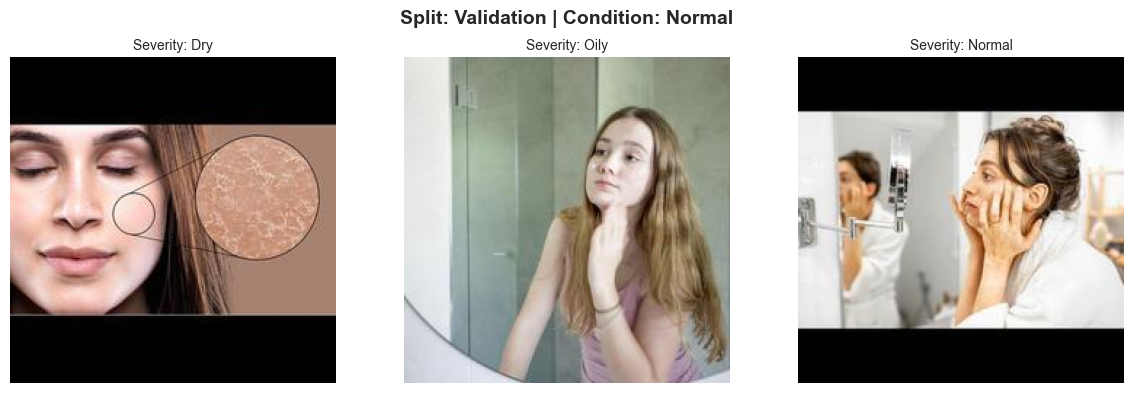

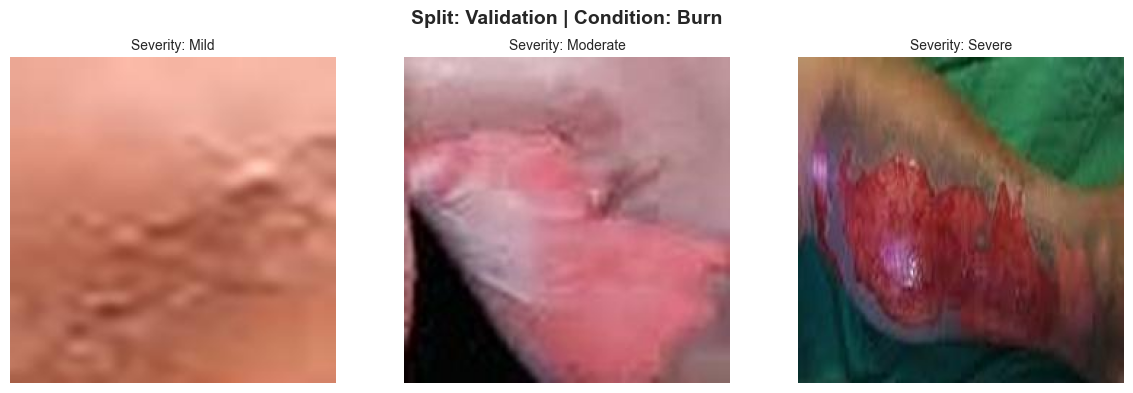

In [32]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Load configuration paths and class structures from the notebook context
SPLITS = ["train", "test", "validation"]

CLASS_STRUCTURE = {
    "acne": ["mild", "moderate", "severe"],
    "eczema": ["mild", "moderate", "severe"],
    "normal": ["dry", "oily", "normal"],
    "burn": ["mild", "moderate", "severe"]
}

def display_class_samples():
    """Displays a sample image for each class type across train, validation, and test splits."""
    for split in SPLITS:
        print(f"\n========================================")
        print(f"Displaying Samples for Split: {split.upper()}")
        print(f"========================================")
        
        for disease, severities in CLASS_STRUCTURE.items():
            fig, axes = plt.subplots(1, len(severities), figsize=(12, 4))
            fig.suptitle(f"Split: {split.capitalize()} | Condition: {disease.capitalize()}", fontsize=14, fontweight="bold")
            
            # Ensure axes is iterable if there's only a single severity level
            if len(severities) == 1:
                axes = [axes]
                
            for idx, severity in enumerate(severities):
                folder = DATASET_DIR / split / disease / severity
                ax = axes[idx]
                ax.axis('off')
                
                if folder.exists():
                    # Find valid image files in the directory
                    image_files = sorted([p for p in folder.iterdir() if p.is_file()])
                    
                    if image_files:
                        # Load and display the first available image
                        img_path = image_files[1]
                        try:
                            with Image.open(img_path) as img:
                                ax.imshow(img)
                                ax.set_title(f"Severity: {severity.capitalize()}", fontsize=10)
                        except Exception as e:
                            ax.set_title(f"{severity}\n(Error loading)", fontsize=10)
                    else:
                        ax.set_title(f"{severity}\n(Empty folder)", fontsize=10)
                else:
                    ax.set_title(f"{severity}\n(Missing folder)", fontsize=10)
                    
            plt.tight_layout()
            plt.savefig(f"{PROJECT_DIR}/results/{split}_{disease}.png")
            plt.show()

# Execute the visualization function
display_class_samples()

# Section 10: Generate metadata.json files

## 10.1 Import libraries and configure metadata

In [17]:
# ============================================================
# Generate Metadata JSON Files
# ============================================================

import json
import pandas as pd

# Image dimensions
IMAGE_HEIGHT = 224
IMAGE_WIDTH = 224
CHANNELS = 3

# Dataset classes
CLASS_STRUCTURE = {
    "acne": ["mild", "moderate", "severe"],
    "eczema": ["mild", "moderate", "severe"],
    "normal": ["dry", "oily", "normal"],
    "burn": ["mild", "moderate", "severe"]
}

print("Metadata configuration completed!")

Metadata configuration completed!


## 10.2 Generate metadata for each disease

In [18]:

# ============================================================
# Create Dataset Metadata JSON
# ============================================================

print("\nProcessing Complete Dataset Metadata")


# ------------------------------------------------------------
# Load Train, Validation and Test CSV Files
# ------------------------------------------------------------

train_df = pd.read_csv(
    METADATA_DIR / "train.csv"
)

validation_df = pd.read_csv(
    METADATA_DIR / "validation.csv"
)

test_df = pd.read_csv(
    METADATA_DIR / "test.csv"
)


# ------------------------------------------------------------
# Combine All Metadata
# ------------------------------------------------------------

combined_df = pd.concat(
    [
        train_df,
        validation_df,
        test_df
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# Extract All Unique Labels
# ------------------------------------------------------------

labels = sorted(
    combined_df["label"]
    .dropna()
    .unique()
    .tolist()
)


# ------------------------------------------------------------
# Create Label Mappings
# ------------------------------------------------------------

label_to_index = {

    label: index

    for index, label in enumerate(labels)

}

index_to_label = {

    str(index): label

    for index, label in enumerate(labels)

}


# ------------------------------------------------------------
# Count Total Images and Labels
# ------------------------------------------------------------

total_images = len(combined_df)

total_labels = len(labels)


# ------------------------------------------------------------
# Count Images in Each Split
# ------------------------------------------------------------

split_counts = {

    "train": len(train_df),

    "validation": len(validation_df),

    "test": len(test_df)

}


# ------------------------------------------------------------
# Create Metadata Dictionary
# ------------------------------------------------------------

metadata = {

    "image_height": IMAGE_HEIGHT,

    "image_width": IMAGE_WIDTH,

    "channels": CHANNELS,

    "total_images": total_images,

    "total_labels": total_labels,

    "labels": labels,

    "label_to_index": label_to_index,

    "index_to_label": index_to_label,

    "split_counts": split_counts

}


# ------------------------------------------------------------
# Save metadata.json
# ------------------------------------------------------------

json_path = METADATA_DIR / "metadata.json"

with open(
    json_path,
    "w",
    encoding="utf-8"
) as json_file:

    json.dump(
        metadata,
        json_file,
        indent=4,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# Display Metadata Summary
# ------------------------------------------------------------

print("\nMetadata saved:", json_path)

print("\nTotal Images:", total_images)

print("Total Labels:", total_labels)

print("\nSplit Counts:")

for split, count in split_counts.items():

    print(f"{split.capitalize()}: {count}")

print("\nLabels:")

for index, label in enumerate(labels):

    print(f"{index}: {label}")


print("\nDataset Metadata JSON Generated Successfully!")


Processing Complete Dataset Metadata

Metadata saved: C:\Users\aurna\Documents\brac_thesis\metadata\metadata.json

Total Images: 9271
Total Labels: 12

Split Counts:
Train: 7021
Validation: 1187
Test: 1063

Labels:
0: Acne_Mild
1: Acne_Moderate
2: Acne_Severe
3: Burn_Mild
4: Burn_Moderate
5: Burn_Severe
6: Eczema_Mild
7: Eczema_Moderate
8: Eczema_Severe
9: Normal_Dry
10: Normal_Normal
11: Normal_Oily

Dataset Metadata JSON Generated Successfully!


## 10.3 Verify generated JSON files

In [19]:

# ============================================================
# Verify Dataset Metadata JSON
# ============================================================

json_path = METADATA_DIR / "metadata.json"

# ------------------------------------------------------------
# Load Metadata JSON
# ------------------------------------------------------------

if not json_path.exists():

    raise FileNotFoundError(
        f"Metadata JSON not found: {json_path}"
    )

with open(
    json_path,
    "r",
    encoding="utf-8"
) as json_file:

    metadata = json.load(json_file)


# ------------------------------------------------------------
# Display Dataset Metadata
# ------------------------------------------------------------

print("\n", "=" * 60)

print("DATASET METADATA VERIFICATION")

print("=" * 60)

print("\nImage Height:", metadata["image_height"])

print("Image Width:", metadata["image_width"])

print("Channels:", metadata["channels"])

print("Total Images:", metadata["total_images"])

print("Total Labels:", metadata["total_labels"])


# ------------------------------------------------------------
# Display Split Counts
# ------------------------------------------------------------

print("\nDataset Split Distribution:")

for split, count in metadata["split_counts"].items():

    print(f"{split.capitalize()}: {count}")


# ------------------------------------------------------------
# Display Label Mappings
# ------------------------------------------------------------

print("\nClass Label Mappings:")

for label in metadata["labels"]:

    print(
        metadata["label_to_index"][label],
        ":",
        label
    )


# ------------------------------------------------------------
# Verify Label Mapping Consistency
# ------------------------------------------------------------

mapping_valid = (

    len(metadata["labels"]) == metadata["total_labels"]

    and len(metadata["label_to_index"]) == metadata["total_labels"]

    and len(metadata["index_to_label"]) == metadata["total_labels"]

    and all(
        metadata["label_to_index"][label] == index
        and metadata["index_to_label"][str(index)] == label
        for index, label in enumerate(metadata["labels"])
    )

)

print("\nLabel Mapping Valid:", mapping_valid)

print("\nJSON Verification Completed!")



DATASET METADATA VERIFICATION

Image Height: 224
Image Width: 224
Channels: 3
Total Images: 9271
Total Labels: 12

Dataset Split Distribution:
Train: 7021
Validation: 1187
Test: 1063

Class Label Mappings:
0 : Acne_Mild
1 : Acne_Moderate
2 : Acne_Severe
3 : Burn_Mild
4 : Burn_Moderate
5 : Burn_Severe
6 : Eczema_Mild
7 : Eczema_Moderate
8 : Eczema_Severe
9 : Normal_Dry
10 : Normal_Normal
11 : Normal_Oily

Label Mapping Valid: True

JSON Verification Completed!
